1) A imagem original da Lena gray possui resolução 512 x 512 pixels. Decime essa imagem para
256 x 256, 128 x 128 e 64 x 64. Exiba as imagens lado a lado e do mesmo tamanho que a imagem
original. Comente.

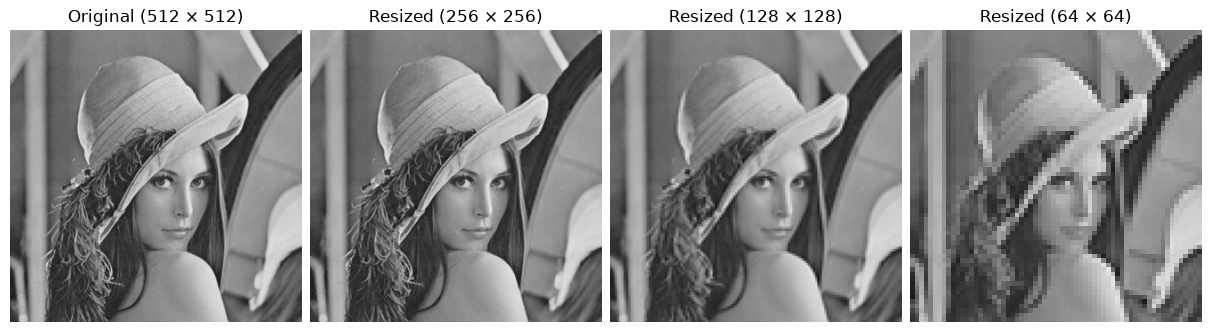

In [9]:
from io import BytesIO
from urllib.request import urlopen

import matplotlib.pyplot as plt
from PIL import Image

image_url = ("https://raw.githubusercontent.com/florencio300/""LISTA-1-PROC-SIN-II/main/dataset/lena2.tif")

with urlopen(image_url) as response:
    original = Image.open(BytesIO(response.read())).convert("RGB")

resized_1 = original.resize((256, 256), Image.Resampling.LANCZOS)
resized_2 = original.resize((128, 128), Image.Resampling.LANCZOS)
resized_3 = original.resize((64, 64), Image.Resampling.LANCZOS)

fig, axes = plt.subplots(1, 4, figsize=(12, 4), constrained_layout=True)

axes[0].imshow(original)
axes[0].set_title(f"Original ({original.width} × {original.height})")
axes[1].imshow(resized_1)
axes[1].set_title("Resized (256 × 256)")
axes[2].imshow(resized_2)
axes[2].set_title("Resized (128 × 128)")
axes[3].imshow(resized_3)
axes[3].set_title("Resized (64 × 64)")

for ax in axes:
    ax.axis("off")
    ax.set_box_aspect(1)

plt.show()

COMENTÁRIO 1

2) Exiba os canais da Lena color. Explique por que cada canal é exibido em níveis de cinza embora
representem as componente R, G e B.

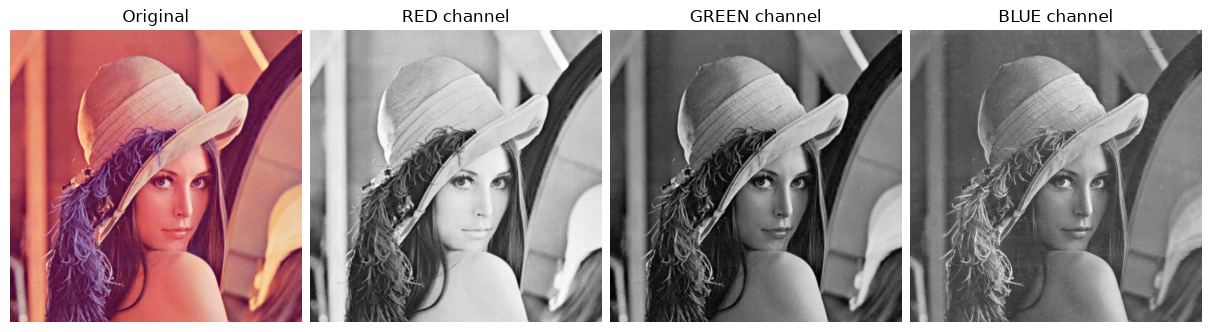

In [1]:
from io import BytesIO
from urllib.request import urlopen
import matplotlib.pyplot as plt
from PIL import Image

image = ("https://raw.githubusercontent.com/florencio300/""LISTA-1-PROC-SIN-II/main/dataset/lena3.tif")

with urlopen(image) as response:
    image = Image.open(BytesIO(response.read()))

image_R = image.getchannel("R")
image_G = image.getchannel("G")
image_B = image.getchannel("B")

fig, axes = plt.subplots(1, 4, figsize=(12, 4), constrained_layout=True)

axes[0].imshow(image)
axes[0].set_title("Original"), 

axes[1].imshow(image_R, cmap="gray",)
axes[1].set_title("RED channel")

axes[2].imshow(image_G, cmap="gray")
axes[2].set_title("GREEN channel")

axes[3].imshow(image_B, cmap="gray")
axes[3 ].set_title("BLUE channel")

for ax in axes:
    ax.axis("off")
    ax.set_box_aspect(1)

plt.show() 

COMENTÁRIO 2 

3) Quantos bits por pixel temos na Lena color e quantos na Lena gray? Quantize a Lena gray com 6,
4, 2 e 1 bit por pixel. Exiba a imagem original e versões quantizadas lado a lado e comente os
resultados.

Image 1: size (512, 512) and  bits: (8, 8, 8).
Image 2: size (512, 512) and  bits: (8,). For this single channel image (grayscale), the number of colors is 2^(num_bits)


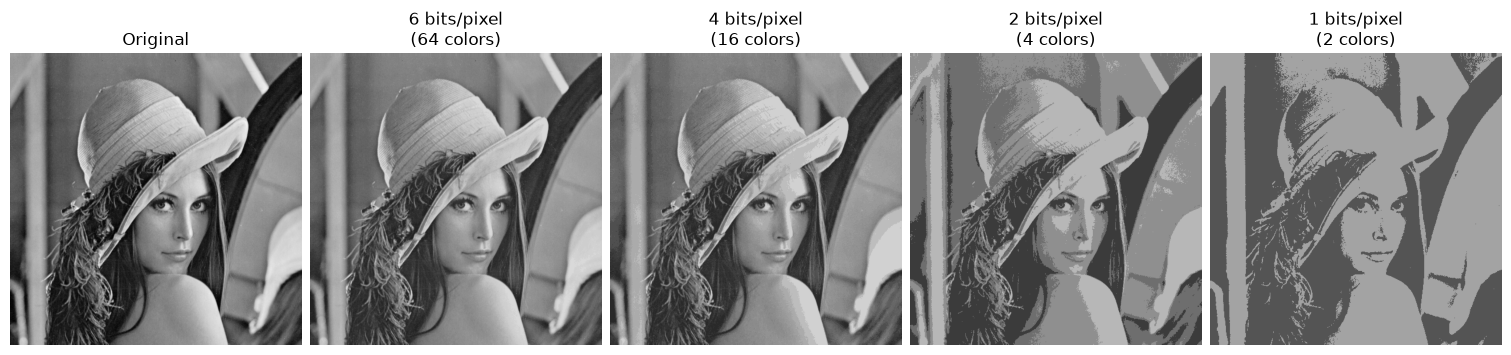

In [2]:
from io import BytesIO
from urllib.request import urlopen
import matplotlib.pyplot as plt
from PIL import Image

image_1 = ("https://raw.githubusercontent.com/florencio300/""LISTA-1-PROC-SIN-II/main/dataset/lena3.tif")
image_2 = ("https://raw.githubusercontent.com/florencio300/""LISTA-1-PROC-SIN-II/main/dataset/lena2.tif")

with urlopen(image_1 ) as response:
    img_1 = Image.open(BytesIO(response.read()))

with urlopen(image_2 ) as response:
    img_2 = Image.open(BytesIO(response.read()))

bits_1 = img_1.tag_v2.get(258)
bits_2 = img_2.tag_v2.get(258)

print(f"Image 1: size {img_1.size} and ", f"bits: {bits_1}.")
print(f"Image 2: size {img_2.size} and ", f"bits: {bits_2}. " f"For this single channel image (grayscale), the number of colors is 2^{"(num_bits)"}")

bits_list = (6, 4, 2, 1)

fig, axes = plt.subplots(1, 5, figsize=(15, 4), constrained_layout=True)

axes[0].imshow(img_2, cmap="gray")
axes[0].set_title("Original")

for ax, bits in zip(axes[1:], bits_list):
    color_count = 2**bits
    quantized = img_2.convert("RGB").quantize(
        colors=color_count,
        method=Image.Quantize.MEDIANCUT,
    )
    ax.imshow(quantized.convert("RGB"))
    ax.set_title(f"{bits} bits/pixel\n({color_count} colors)")

for ax in axes:
    ax.axis("off")
    ax.set_box_aspect(1)

plt.show() 

COMENTÁRIO 3

4) Crie uma imagem sintética cinza (resolução 256 x 256 pixels) com nível 128. Crie um quadrado
(32x32 pixels) no centro e aumente o nível de cinza desse quadrado até que ele esteja no limite da
percepção. Repita o processo, mas dessa vez diminuindo o nível de cinza do quadrado central. Você
nota alguma ilusão de óptica? Comente os resultados e explique por que a percepção humana do
brilho é uniforme no logaritmo da luminância.

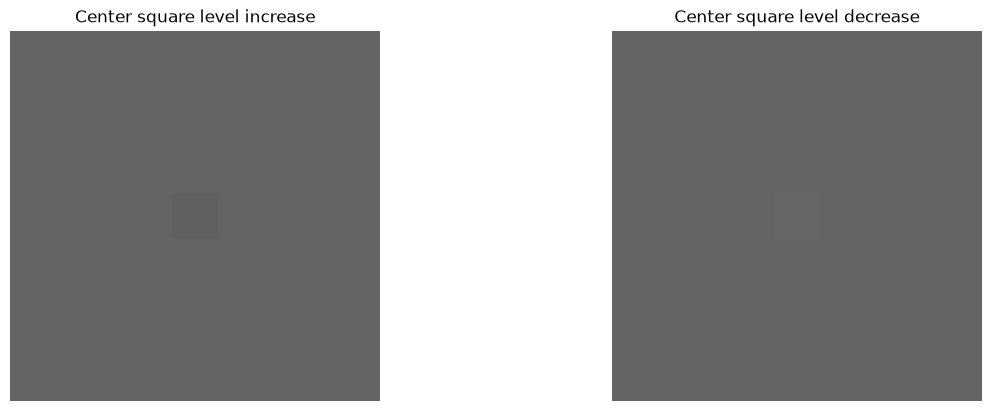

In [3]:
import numpy as np
import matplotlib.pyplot as plt

square1 = np.full((256, 256), 50, dtype=np.uint8)  

square1[112:144, 112:144] = 49.9999999999999964
  
square2 = np.full((256, 256), 50, dtype=np.uint8)  

square2[112:144, 112:144] = 50.99999999999999645

fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
axes[0].imshow(square1, cmap="gray", vmin=0, vmax=128, interpolation="nearest")
axes[0].set_title("Center square level increase")
axes[1].imshow(square2, cmap="gray", vmin=0, vmax=128, interpolation="nearest")
axes[1].set_title("Center square level decrease")

for ax in axes:
    ax.axis("off")
plt.show()

COMENTÁRIO 4

5) Considere a imagem Frog. Aplique um ajuste de brilho a partir do escalonamento da intensidade.
Use um ajuste na escala de 1.2. Exiba as imagens lado a lado e comente os resultados.


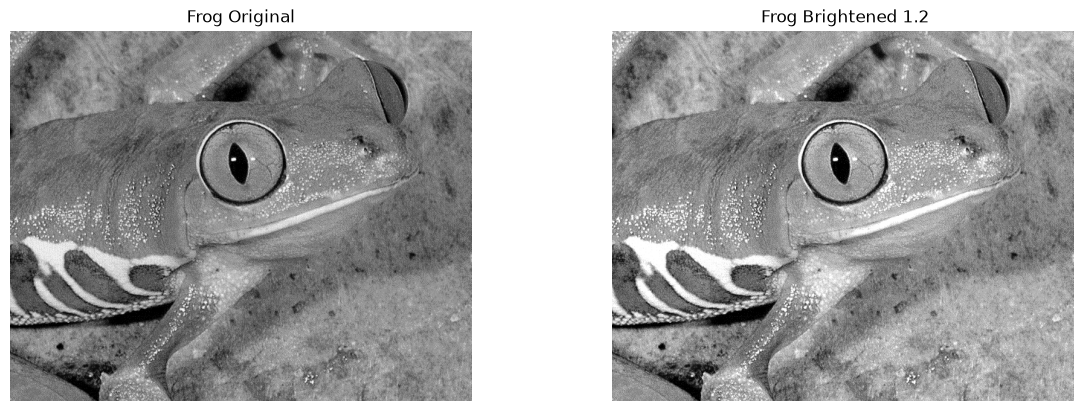

In [1]:
from io import BytesIO
from urllib.request import urlopen
import matplotlib.pyplot as plt
from PIL import Image, ImageEnhance

frog = ("https://raw.githubusercontent.com/florencio300/""LISTA-1-PROC-SIN-II/main/dataset/frog.tif")

with urlopen(frog) as response:
    frog = Image.open(BytesIO(response.read()))

image_bright = ImageEnhance.Brightness(frog).enhance(1.2)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)

axes[0].imshow(frog, cmap="gray")
axes[0].set_title("Frog Original"), 

axes[1].imshow(image_bright, cmap="gray",)
axes[1].set_title(" Frog Brightened 1.2") 

for ax in axes:
    ax.axis('off')
plt.show()

COMENTÁRIO 5

6) Considere a imagem Frog. Aplique um ajuste de contraste a partir da modificação do gamma.
Use gamma = 1.5. Exiba as imagens lado a lado e comente os resultados.


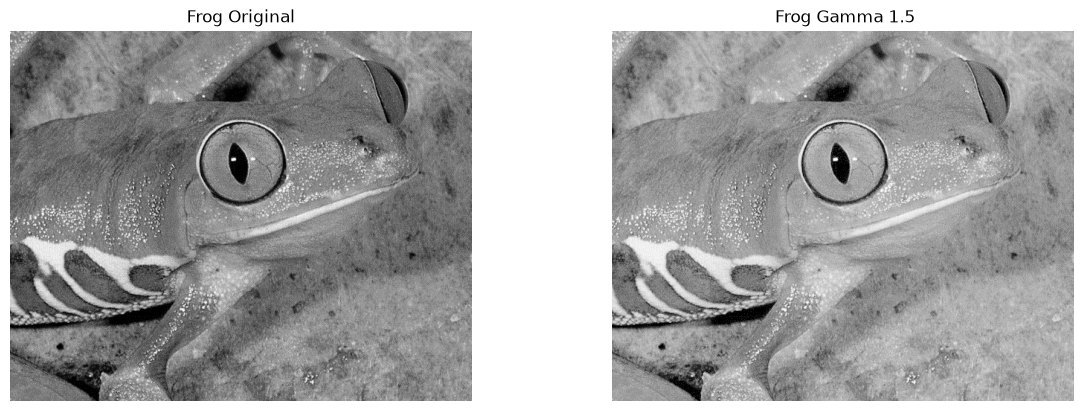

In [2]:
from io import BytesIO
from urllib.request import urlopen
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np

frog = ("https://raw.githubusercontent.com/florencio300/""LISTA-1-PROC-SIN-II/main/dataset/frog.tif")

with urlopen(frog) as response:
    frog = Image.open(BytesIO(response.read()))

frog_array = np.array(frog, dtype=np.float32) / 255.0

gamma = 1.5
gamma_frog_array = 255.0 * (frog_array ** (1/ gamma))
gamma_array = np.clip(gamma_frog_array, 0, 255).astype(np.uint8)
img_gamma_corrected = Image.fromarray(gamma_array)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)

axes[0].imshow(frog, cmap="gray")
axes[0].set_title("Frog Original"), 

axes[1].imshow(img_gamma_corrected, cmap="gray",)
axes[1].set_title(" Frog Gamma 1.5") 

for ax in axes:
    ax.axis('off')
plt.show()

COMENTÁRIO 6

7) Crie 32 imagens com ruído gaussiano a partir da imagem Brain. Aplique a técnica de supressão
de ruído a partir da média das imagens. Compare com a imagem original.

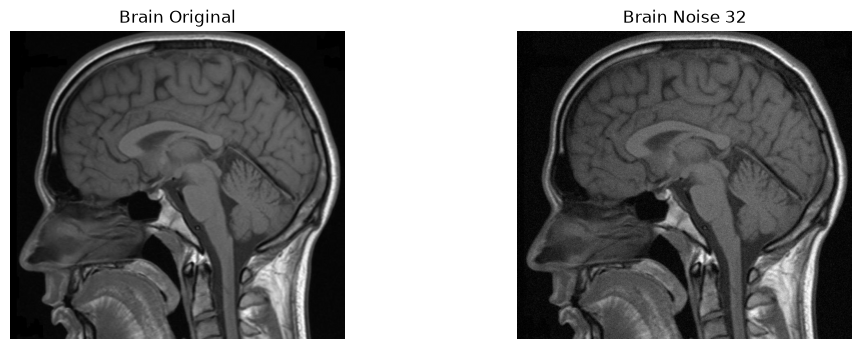

In [ ]:
from io import BytesIO
from urllib.request import urlopen
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np

brain = ("https://raw.githubusercontent.com/florencio300/""LISTA-1-PROC-SIN-II/main/dataset/brain.jpg")

with urlopen(brain) as response:
    brain = Image.open(BytesIO(response.read()))

brain_array = np.array(brain, dtype=np.float32)

num_images = 32
mean = 0
sigma = 50 # Era 25 mas não achei visível o suficiente então dupliquei

noisy_images = []

for i in range(num_images):
    noise = np.random.normal(mean, sigma, brain_array.shape)
    noisy_array = brain_array + noise
    noisy_array_clipped = np.clip(noisy_array, 0, 255).astype(np.uint8)
    noisy_images.append(noisy_array_clipped)

noisy_stack = np.array(noisy_images)

#______________________________________________________________________________________________________________________________________________________________________________

# Deixei a seção abaixo comentada para não exibir todas as imagens com ruído. 
# Senti a necessidade de verificar se o ruído estava sendo aplicado corretamente.
# Testei com a constante de ruído sigma = 25 e não achei visível o suficiente, então dupliquei para sigma = 50.

#______________________________________________________________________________________________________________________________________________________________________________
#display_images = [Image.fromarray(noisy_stack[i]) for i in range(num_images)]

#fig, axes = plt.subplots(8, 4, figsize=(12, 24), constrained_layout=True)

#for i, ax in enumerate(axes.flat):
    #ax.imshow(display_images[i], cmap="gray")
    #ax.axis('off')
#______________________________________________________________________________________________________________________________________________________________________________

median_array = np.median(noisy_stack, axis=0).astype(np.uint8)

final_median_img = Image.fromarray(median_array)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].imshow(brain, cmap="gray")
axes[0].set_title("Brain Original")

axes[1].imshow(final_median_img, cmap="gray")
axes[1].set_title("Brain Noise 32")

for ax in axes:
    ax.axis('off')
plt.show()

plt.show()

COMENTÁRIO 7

8) Calcule e exiba os histogramas das imagens Lena gray, Moon, Bay e Brain. Relacione o formato
dos histogramas com as características das imagens.


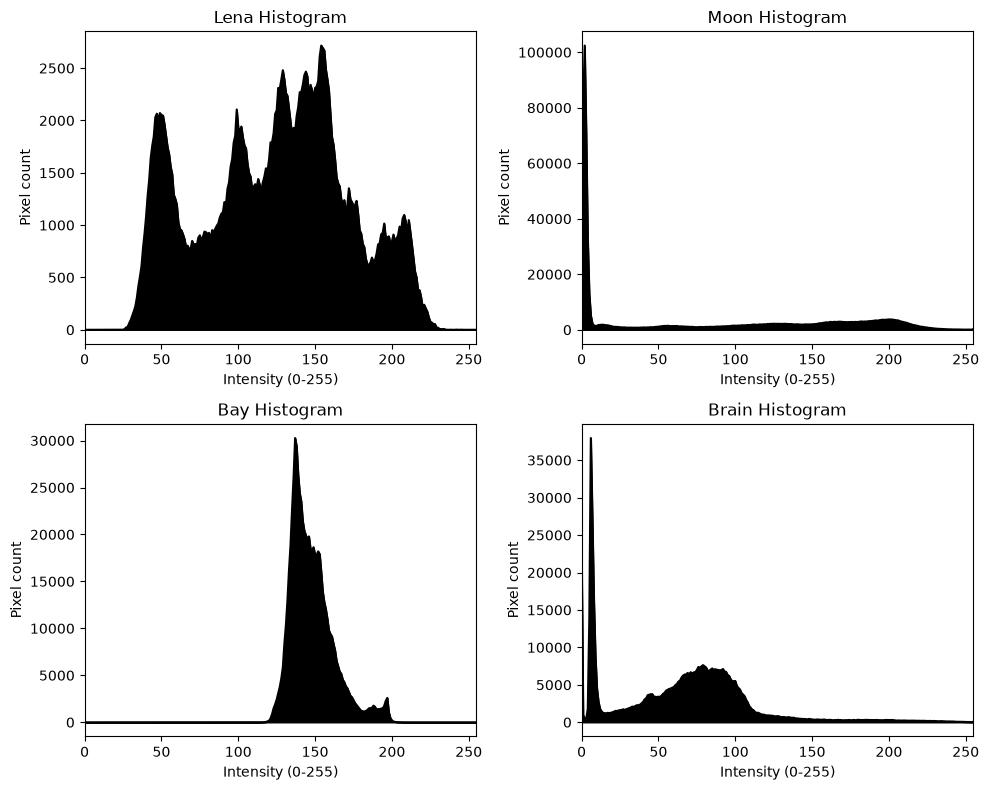

In [1]:
from io import BytesIO
from urllib.request import urlopen
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np

Lena = ("https://raw.githubusercontent.com/florencio300/""LISTA-1-PROC-SIN-II/main/dataset/lena2.tif")
Moon = ("https://raw.githubusercontent.com/florencio300/""LISTA-1-PROC-SIN-II/main/dataset/moon.jpg")
Bay = ("https://raw.githubusercontent.com/florencio300/""LISTA-1-PROC-SIN-II/main/dataset/bay.jpg")
Brain = ("https://raw.githubusercontent.com/florencio300/""LISTA-1-PROC-SIN-II/main/dataset/brain.jpg")

with urlopen(Lena) as response:
    lena = Image.open(BytesIO(response.read())) 
with urlopen(Moon) as response:
    moon = Image.open(BytesIO(response.read())) 
with urlopen(Bay) as response:
    bay = Image.open(BytesIO(response.read()))  
with urlopen(Brain) as response:
    brain = Image.open(BytesIO(response.read()))

images = {"Lena": lena,"Moon": moon,"Bay": bay,"Brain": brain,}

fig, axes = plt.subplots(2, 2, figsize=(10, 8))

black = "black"

for ax, (name, image) in zip(axes.flat, images.items()):
    pixels = np.asarray(image)
    histogram, _ = np.histogram(pixels.ravel(), bins=256, range=(0, 256))
    intensities = np.arange(256)

    ax.fill_between(intensities, histogram, color=black, alpha=1.0)
    ax.plot(intensities, histogram, color=black)
    ax.set_xlabel("Intensity (0-255)")
    ax.set_ylabel("Pixel count")
    ax.set_title(f"{name} Histogram")
    ax.set_xlim(0, 255)

plt.tight_layout()
plt.show()

COMENTÁRIO 8

9) Aplique a equalização de histogramas nas imagens Lena gray, Moon, Bay e Brain. Compare o
resultado com as imagens originais.


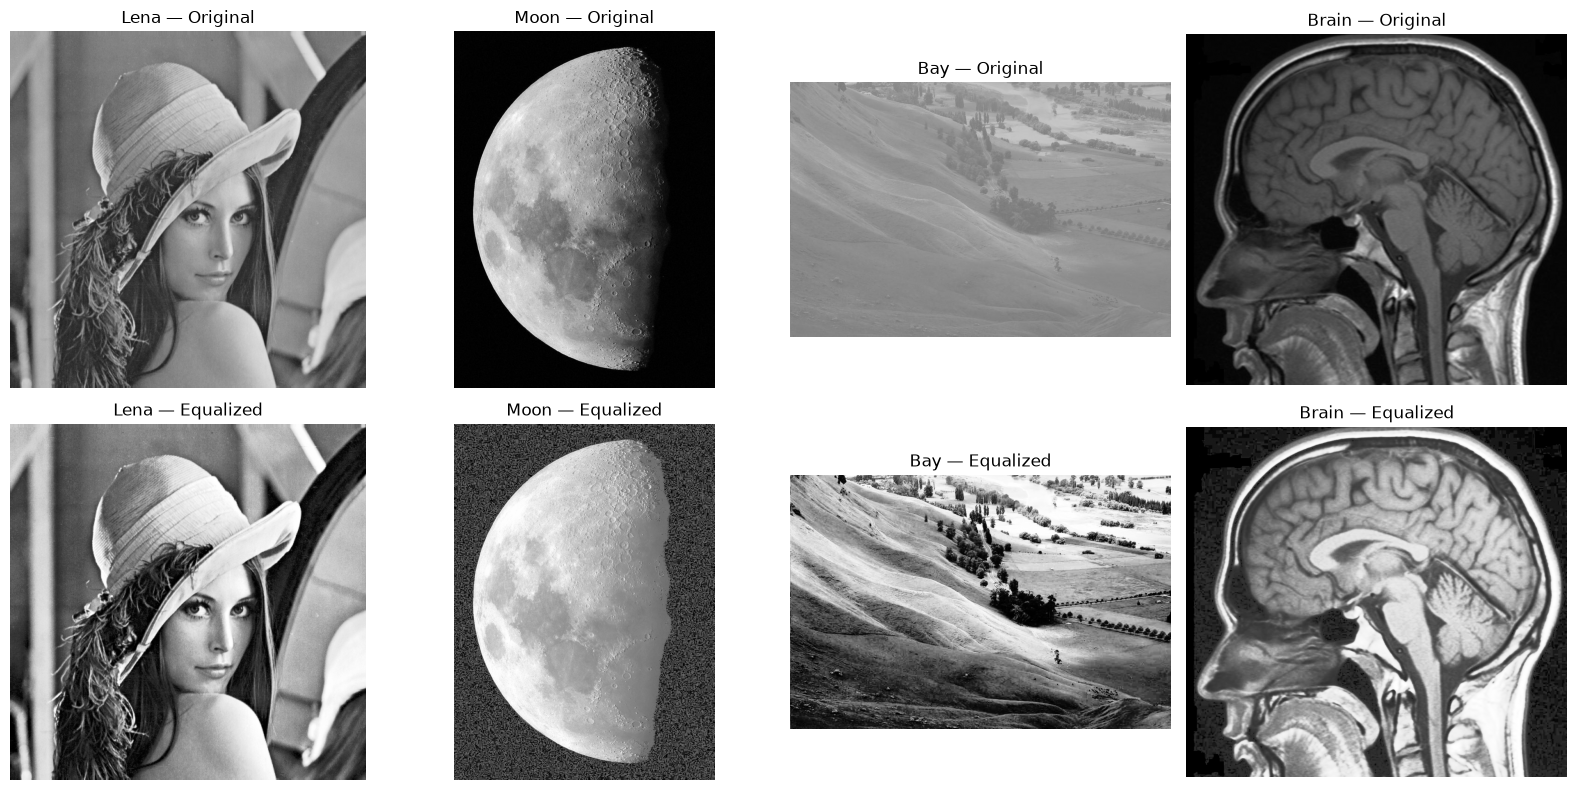

In [2]:
from io import BytesIO
from urllib.request import urlopen
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np

Lena = ("https://raw.githubusercontent.com/florencio300/""LISTA-1-PROC-SIN-II/main/dataset/lena2.tif")
Moon = ("https://raw.githubusercontent.com/florencio300/""LISTA-1-PROC-SIN-II/main/dataset/moon.jpg")
Bay = ("https://raw.githubusercontent.com/florencio300/""LISTA-1-PROC-SIN-II/main/dataset/bay.jpg")
Brain = ("https://raw.githubusercontent.com/florencio300/""LISTA-1-PROC-SIN-II/main/dataset/brain.jpg")

with urlopen(Lena) as response:
    lena = Image.open(BytesIO(response.read())) 
with urlopen(Moon) as response:
    moon = Image.open(BytesIO(response.read())) 
with urlopen(Bay) as response:
    bay = Image.open(BytesIO(response.read()))  
with urlopen(Brain) as response:
    brain = Image.open(BytesIO(response.read()))

images = {"Lena": lena,"Moon": moon,"Bay": bay,"Brain": brain,}

histograms = {}
equalized_histograms = {}
equalized_images = {}

fig, axes = plt.subplots(2, len(images), figsize=(4 * len(images), 8), squeeze=False)

for col, (name, image) in enumerate(images.items()):
    pixels = np.asarray(image, dtype=np.uint8)
 
    histogram, _ = np.histogram(pixels.ravel(), bins=256, range=(0, 256))

    pxl_ntst = histogram.cumsum()
    pxl_ntst_min = pxl_ntst[pxl_ntst > 0][0]

    if pxl_ntst_min == pixels.size:  
        equalized_pixels = pixels.copy()
    else:
        lookup_table = np.rint((pxl_ntst - pxl_ntst_min) * 255 / (pixels.size - pxl_ntst_min)).clip(0, 255).astype(np.uint8)
        equalized_pixels = lookup_table[pixels]

    equalized_images[name] = Image.fromarray(equalized_pixels)

    axes[0, col].imshow(pixels, cmap="gray", vmin=0, vmax=255)
    axes[0, col].set_title(f"{name} — Original")
    axes[0, col].axis("off")

    axes[1, col].imshow(equalized_pixels, cmap="gray", vmin=0, vmax=255)
    axes[1, col].set_title(f"{name} — Equalized")
    axes[1, col].axis("off")

plt.tight_layout()
plt.show()

COMENTÁRIO 9

10) Aplique a equalização adaptativa de histogramas nas imagens Lena gray, Moon, Bay e Brain.
Utilize blocos de tamanho 8x8 e 16x16 pixels. Compare os resultados com o que foi obtido na
Questão 9. 

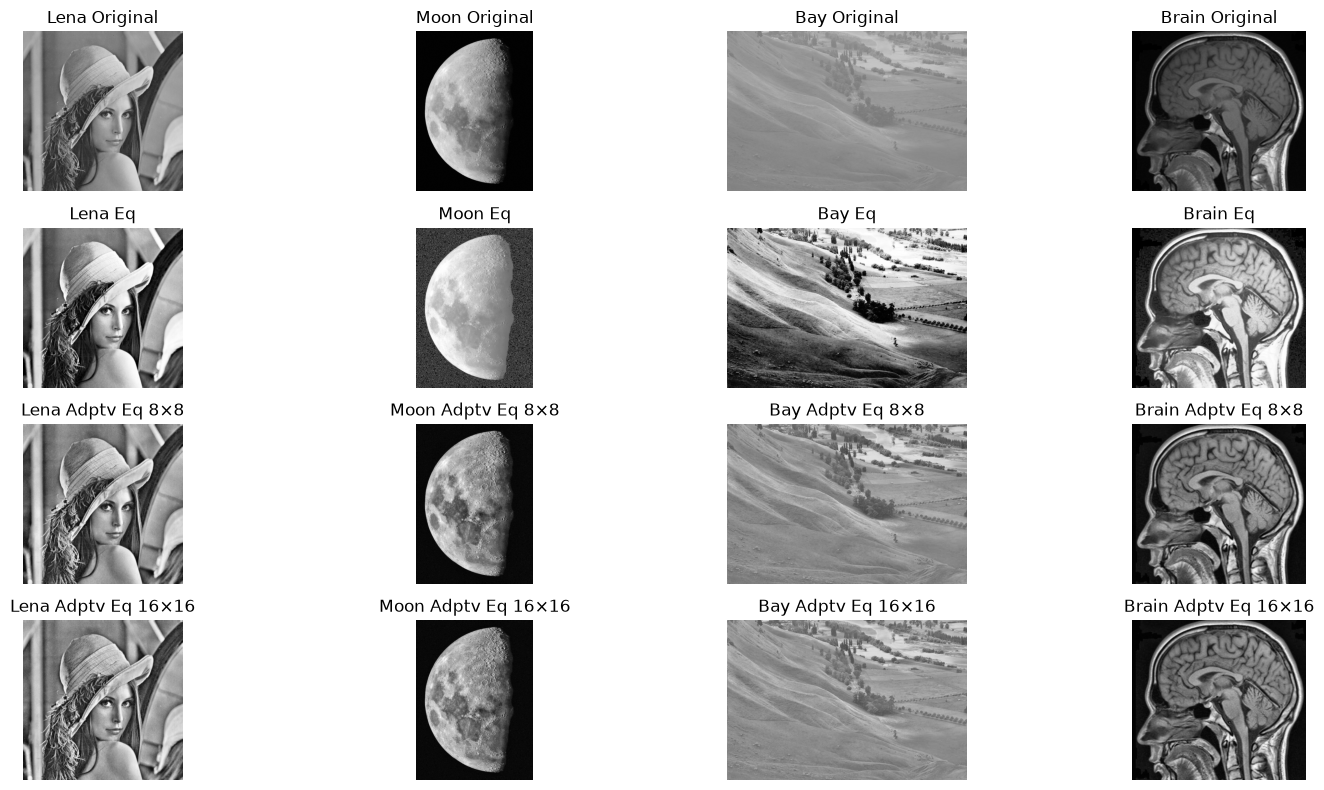

In [4]:
from io import BytesIO
from urllib.request import urlopen
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np
import cv2

Lena = ("https://raw.githubusercontent.com/florencio300/""LISTA-1-PROC-SIN-II/main/dataset/lena2.tif")
Moon = ("https://raw.githubusercontent.com/florencio300/""LISTA-1-PROC-SIN-II/main/dataset/moon.jpg")
Bay = ("https://raw.githubusercontent.com/florencio300/""LISTA-1-PROC-SIN-II/main/dataset/bay.jpg")
Brain = ("https://raw.githubusercontent.com/florencio300/""LISTA-1-PROC-SIN-II/main/dataset/brain.jpg")

with urlopen(Lena) as response:
    lena = Image.open(BytesIO(response.read())) 
with urlopen(Moon) as response:
    moon = Image.open(BytesIO(response.read())) 
with urlopen(Bay) as response:
    bay = Image.open(BytesIO(response.read()))  
with urlopen(Brain) as response:
    brain = Image.open(BytesIO(response.read()))

images = {"Lena": lena,"Moon": moon,"Bay": bay,"Brain": brain,}
histograms = {}
equalized_histograms = {}
equalized_images = {}
adaptive_equalized_images = {(8, 8): {},(16, 16): {},}
adaptive_equalized_histograms = {(8, 8): {},(16, 16): {},}

tile_grids = [(8, 8), (16, 16)]

fig, axes = plt.subplots(4, len(images), figsize=(4 * len(images), 8), squeeze=False)

for col, (name, image) in enumerate(images.items()):
    pixels = np.asarray(image, dtype=np.uint8)
 
    histogram, _ = np.histogram(pixels.ravel(), bins=256, range=(0, 256))

    pxl_ntst = histogram.cumsum()
    pxl_ntst_min = pxl_ntst[pxl_ntst > 0][0]

    if pxl_ntst_min == pixels.size:  
        equalized_pixels = pixels.copy()
    else:
        lookup_table = np.rint((pxl_ntst - pxl_ntst_min) * 255 / (pixels.size - pxl_ntst_min)).clip(0, 255).astype(np.uint8)
        equalized_pixels = lookup_table[pixels]

    equalized_images[name] = Image.fromarray(equalized_pixels)

    for row, tile_grid in enumerate(tile_grids, start=2):
        clahe = cv2.createCLAHE(clipLimit=2.0,tileGridSize=tile_grid,)
        adaptive_equalized_pixels = clahe.apply(pixels)

        adaptive_equalized_images[tile_grid][name] = Image.fromarray(adaptive_equalized_pixels)
        adaptive_equalized_histograms[tile_grid][name], _ = np.histogram(adaptive_equalized_pixels.ravel(), bins=256, range=(0, 256))

        axes[0, col].imshow(pixels, cmap="gray", vmin=0, vmax=255)
        axes[0, col].set_title(f"{name} Original")
        axes[0, col].axis("off")
        
        axes[1, col].imshow(equalized_pixels, cmap="gray", vmin=0, vmax=255)
        axes[1, col].set_title(f"{name} Eq")
        axes[1, col].axis("off")
        
        axes[row, col].imshow(adaptive_equalized_pixels, cmap="gray", vmin=0, vmax=255)
        axes[row, col].set_title(f"{name} Adptv Eq {tile_grid[0]}×{tile_grid[1]}")
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

COMENTÁRIO 10

11) Exiba a imagem Balloons lado a lado com os seus canais R, G e B. Os canais devem ser
exibidos como imagens monocromáticas. Explique.


In [ ]:
from io import BytesIO
from urllib.request import urlopen

import matplotlib.pyplot as plt
from PIL import Image

image_url = ("https://raw.githubusercontent.com/florencio300/""LISTA-1-PROC-SIN-II/main/dataset/balloons.tif")

with urlopen(image_url) as response:
    original = Image.open(BytesIO(response.read())).convert("RGB")

R = original.getchannel("R")
G = original.getchannel("G")    
B = original.getchannel("B")

fig, axes = plt.subplots(1, 4, figsize=(18, 4), constrained_layout=True)

axes[0].imshow(original)
axes[0].set_title(f"Balloons Original")
axes[1].imshow(R, cmap= "Reds")
axes[1].set_title(f"Balloons R")
axes[2].imshow(G, cmap= "Greens")
axes[2].set_title(f"Balloons G")
axes[3].imshow(B, cmap= "Blues")
axes[3].set_title(f"Balloons B")

for ax in axes:
    ax.axis("off")

COMENTÁRIO 11

12) Converta a imagem Balloons para níveis de cinza a partir da média dos canais. Em seguida
converta utilizando a função de conversão padrão. Exiba as imagens lado a lado e explique por que
elas são diferentes.

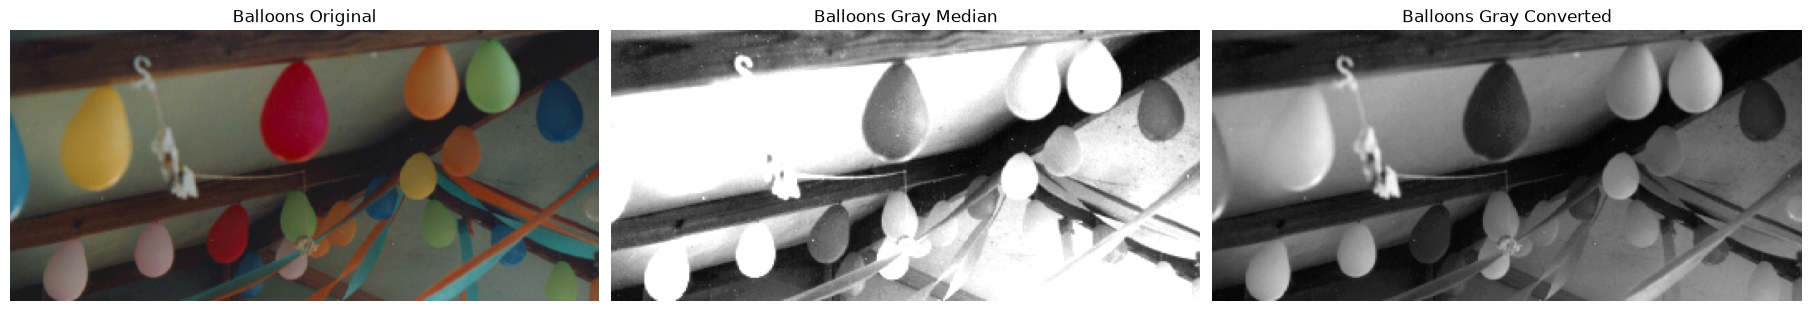

In [5]:
from io import BytesIO
from urllib.request import urlopen
from PIL import Image
import numpy as np

image_url = ("https://raw.githubusercontent.com/florencio300/""LISTA-1-PROC-SIN-II/main/dataset/balloons.tif")

with urlopen(image_url) as response:
    original = Image.open(BytesIO(response.read())).convert("RGB")

original_gray = original.convert("L")

R = original.getchannel("R")
G = original.getchannel("G")    
B = original.getchannel("B")

R_array = np.array(R, dtype=np.float32)
G_array = np.array(G, dtype=np.float32)
B_array = np.array(B, dtype=np.float32)

RGB_images = []

RGB_array = R_array + G_array + B_array

RGB_array_clipped = np.clip(RGB_array, 0, 255).astype(np.uint8)
RGB_images.append(RGB_array_clipped)

RGB_stack = np.array(RGB_images)

median_array = np.median(RGB_stack, axis=0).astype(np.uint8)

final_median_img = Image.fromarray(median_array)

fig, axes = plt.subplots(1, 3, figsize=(18, 4), constrained_layout=True)

axes[0].imshow(original)
axes[0].set_title(f"Balloons Original")
axes[1].imshow(final_median_img, cmap= "gray")
axes[1].set_title(f"Balloons Gray Median",)
axes[2].imshow(original_gray, cmap="gray")
axes[2].set_title(f"Balloons Gray Converted")

for ax in axes:
    ax.axis("off")

COMENTÁRIO 12

13) Converta a imagem Peppers_color para níveis de cinza. Aplique uma binarização por limiar
global para destacar apenas a cor vermelha. Em seguida, use a imagem binária como máscara e
aplique na imagem original. Explique por que a segmentação contém algumas imperfeições
indesejadas.

COMENTÁRIO 13

14) Converta a imagem Guia para níveis de cinza e em seguida aplique o Otsu global. Em seguida,
aplique a binarização localmente adaptativa. Use a variância como medida de uniformidade. Qual é
o tamanho de janela que acarreta em melhor resultado?

COMENTÁRIO 14